# Tissue composition: more microglia in responder white matter, not piled on stressed OLs

Earlier notebooks measured *states* (ISR in OLs, DAM in microglia). This one counts *cells*: do responders gain
microglia or lose oligodendrocytes, where, and is it local to stressed OLs? Module: `utils/composition.py`.

* **A.** Region coverage per mouse: are the same regions sampled in every section?
* **B.** Cell densities (cells / mm2 of region) per region and cell type, responders and non-responders vs controls.
* **C.** Label-free check: microglia density in grid squares stratified by OL fraction (white-matter proxy).
* **D.** Are the extra microglia proliferating (count-adjusted)?
* **E.** Are microglia concentrated around stressed OLs, or spread through the region?
* **F.** Maps.

OL counts include DA-OLs (analysis/02: the DA-OL label partly captures responding OLs, so counting OL and DA-OL
separately would show relabelling, not loss). Inputs: `results/cell_table/cells.csv.gz`, `cell_gene_scores.csv.gz`,
`ol_gene_scores.csv.gz` (all local). Tests: exact permutation over mice (smallest p = 1/84 = 0.012).

In [1]:
import sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.api as sm
REPO = Path.cwd().resolve().parent; sys.path.insert(0, str(REPO))
from utils import composition as co, mosaic as mo

OUT = REPO / "results" / "composition"; FIG = OUT / "figures"; TAB = OUT / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
sections = pd.read_csv(REPO / "results" / "sample_classifier" / "tables" / "sections_with_responder_calls.csv", index_col=0)
grp = sections["group"]; ctrl = sections.index[grp == "control"]; resp = sections.index[grp == "responder"]
nonr = sections.index[grp == "non-responder"]
order = list(ctrl) + list(nonr) + list(resp)
cells = pd.read_csv(REPO / "results" / "cell_table" / "cells.csv.gz")
sc = pd.read_csv(REPO / "results" / "cell_table" / "cell_gene_scores.csv.gz", usecols=["cell_id", "sample_id", "total_counts", "PROLIF", "DAM"])
cells = cells.merge(sc, on=["cell_id", "sample_id"]).rename(columns={"RBD_compartment_simplified": "region"})
cells["cell_type"] = cells.cell_class.replace({"DA-Oligodendrocytes": "Oligodendrocytes"})
print(f"{len(cells):,} cells in {cells.sample_id.nunique()} sections")

INK2, AXIS = "#52514e", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({"axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 9, "axes.titlelocation": "left"})
GROUP_ORDER = ["control", "non-responder", "responder"]
STYLE = {"control": dict(color=BLUE), "non-responder": dict(facecolor="white", edgecolor=ORANGE), "responder": dict(color=ORANGE)}
def save(fig, name, dpi=200):
    fig.savefig(FIG / f"{name}.png", dpi=dpi, bbox_inches="tight"); fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
def save_table(df, name, index=True):
    df.to_csv(TAB / f"{name}.csv", index=index); return df
def dots(ax, values, title, ylab=None, ref=None):
    for gi, g in enumerate(GROUP_ORDER):
        v = values[values.index.map(grp) == g].to_numpy()
        ax.scatter(np.full(len(v), gi) + np.linspace(-0.12, 0.12, len(v)), v, s=46, linewidth=1.4, zorder=3, **STYLE[g])
    if ref is not None: ax.axhline(ref, color=AXIS, lw=0.8)
    ax.set_xticks(range(3), ["ctrl", "non-resp", "resp"]); ax.set_xlim(-0.5, 2.5); ax.set_title(title, fontsize=9)
    if ylab: ax.set_ylabel(ylab)
def ptxt(v):
    _, pr = co.exact_perm(v, resp, ctrl); _, pn = co.exact_perm(v, nonr, ctrl)
    return f"resp p={pr:.3f}, non-resp p={pn:.2f}"

980,474 cells in 12 sections


## A. Region coverage

,Cortex,Thalamus,Striatum,Hypothalamus,Fiber tracts,Hippocampus,Pallidum,Olfactory areas,Ventricular system,Meningeal border/glia limitans,Vasculature,Unknown
responders,28.583,12.803,12.370,11.317,9.817,3.587,0.397,7.970,3.720,7.520,1.030,0.877
controls,25.643,13.617,13.395,10.927,6.988,3.178,3.635,7.457,4.743,5.827,0.858,3.728
p,0.357,0.429,0.702,0.774,0.012,0.548,0.012,0.821,0.060,0.167,0.452,0.655


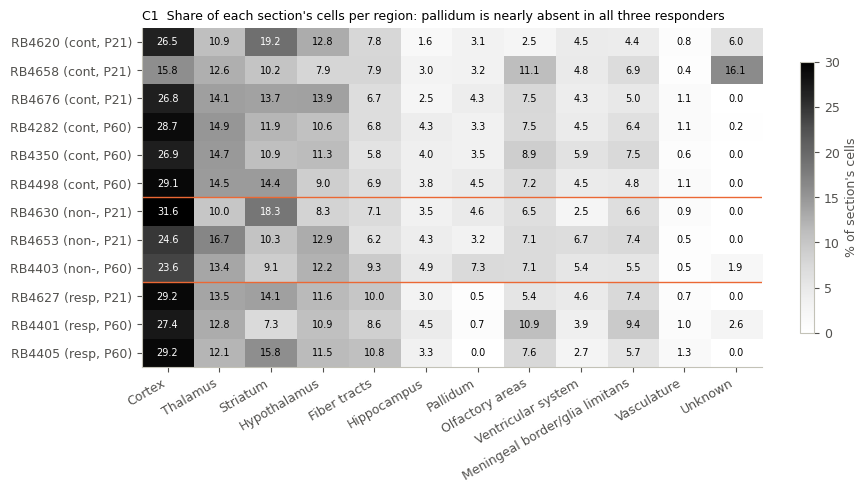

In [2]:
REG = ["Cortex", "Thalamus", "Striatum", "Hypothalamus", "Fiber tracts", "Hippocampus", "Pallidum", "Olfactory areas",
       "Ventricular system", "Meningeal border/glia limitans", "Vasculature", "Unknown"]
cov = save_table((cells.groupby(["sample_id", "region"]).size().unstack().fillna(0)
                  .pipe(lambda t: 100 * t.div(t.sum(1), axis=0)).loc[order, REG]).round(2), "region_coverage_pct")
fig, ax = plt.subplots(figsize=(10, 4.4))
im = ax.imshow(cov, cmap="Greys", aspect="auto", vmax=30)
for i in range(cov.shape[0]):
    for j in range(cov.shape[1]):
        ax.text(j, i, f"{cov.iat[i, j]:.1f}", ha="center", va="center", fontsize=7, color="w" if cov.iat[i, j] > 18 else "k")
ax.set_xticks(range(len(REG)), REG, rotation=30, ha="right"); ax.set_yticks(range(len(order)), [f"{s} ({grp[s][:4]}, P{sections.age[s]})" for s in order])
for y in (len(ctrl) - 0.5, len(ctrl) + len(nonr) - 0.5): ax.axhline(y, color=ORANGE, lw=1)
fig.colorbar(im, ax=ax, shrink=0.8, label="% of section's cells")
ax.set_title("C1  Share of each section's cells per region: pallidum is nearly absent in all three responders", fontsize=9)
save(fig, "C1_region_coverage")
display(pd.DataFrame({r: [cov.loc[resp, r].mean(), cov.loc[ctrl, r].mean(), co.exact_perm(cov[r], resp, ctrl)[1]] for r in REG},
                     index=["responders", "controls", "p"]).round(3))

**A.** Most regions are sampled at similar shares in all twelve sections, with one exception: **pallidum makes up
0.0-0.7 % of cells in the three responders against 3.1-7.3 % in every control and non-responder** (p = 0.012), while
fibre tracts are slightly larger in responders. Either the responder sections were cut at a plane with less
pallidum (it lies next to the internal capsule), or the disease shifts the transcriptome-based region calls (the RBD compartments
come from pooled neighbourhood transcripts, so a white-matter-rich pallidum with many stressed OLs and microglia
could be absorbed into "fibre tracts"). That is why section C repeats the key result without region labels.

*Resolved in analysis/14:* a map re-drawn from disease-free genes restores pallidum in the responders, so the
disease distorted the original region calls; thalamus microgliosis holds on the new map, the fibre-tract excess is
partly pallidum.

## B. Cell densities per region

,cell_type,region,metric,ctrl_mean,resp_mean,nonresp_mean,log2_resp_vs_ctrl,p_resp,log2_nonresp_vs_ctrl,p_nonresp
0,Microglia,Thalamus,density,70.8471,119.7406,67.4820,0.7571,0.0119,-0.0702,0.6429
2,Microglia,Fiber tracts,density,60.2813,134.4357,68.8216,1.1571,0.0119,0.1911,0.1548
64,Excitatory Neurons,Hypothalamus,density,0.4295,2.3404,1.4047,2.4462,0.0238,1.7097,0.0595
74,Neurons,Fiber tracts,density,24.0614,88.3347,29.3916,1.8763,0.0238,0.2887,0.6548
14,Oligodendrocytes,Fiber tracts,density,1673.5736,1395.6527,1675.2774,-0.2620,0.0357,0.0015,1.0000
20,Oligodendrocytes,Cortex,density,324.6781,245.9870,310.2587,-0.4004,0.0357,-0.0655,0.8095
4,Microglia,Hypothalamus,density,64.6874,93.1002,68.4860,0.5253,0.0595,0.0823,0.6786
12,Oligodendrocytes,Thalamus,density,596.7844,488.1151,653.3531,-0.2900,0.0714,0.1307,0.4167
32,Immature Oligodendrocytes I,Cortex,density,59.8728,55.0856,63.4324,-0.1202,0.0833,0.0833,0.3095


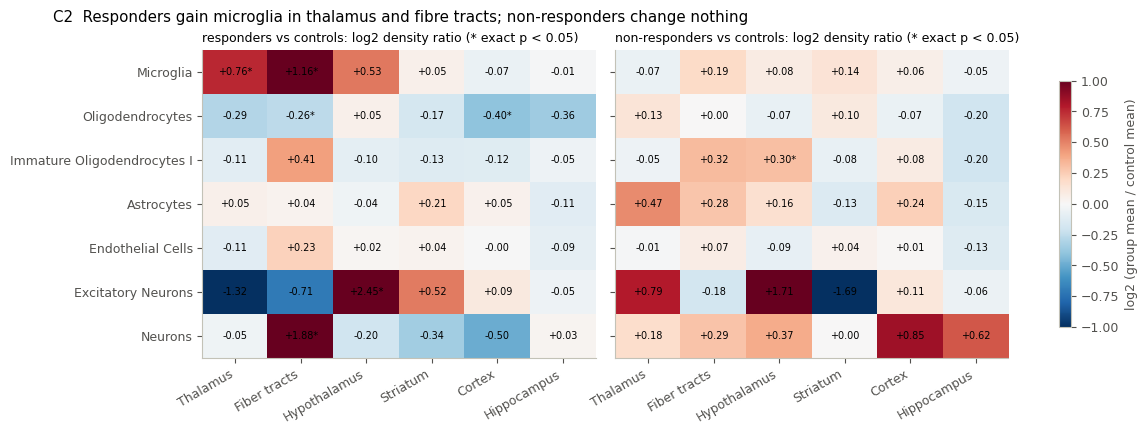

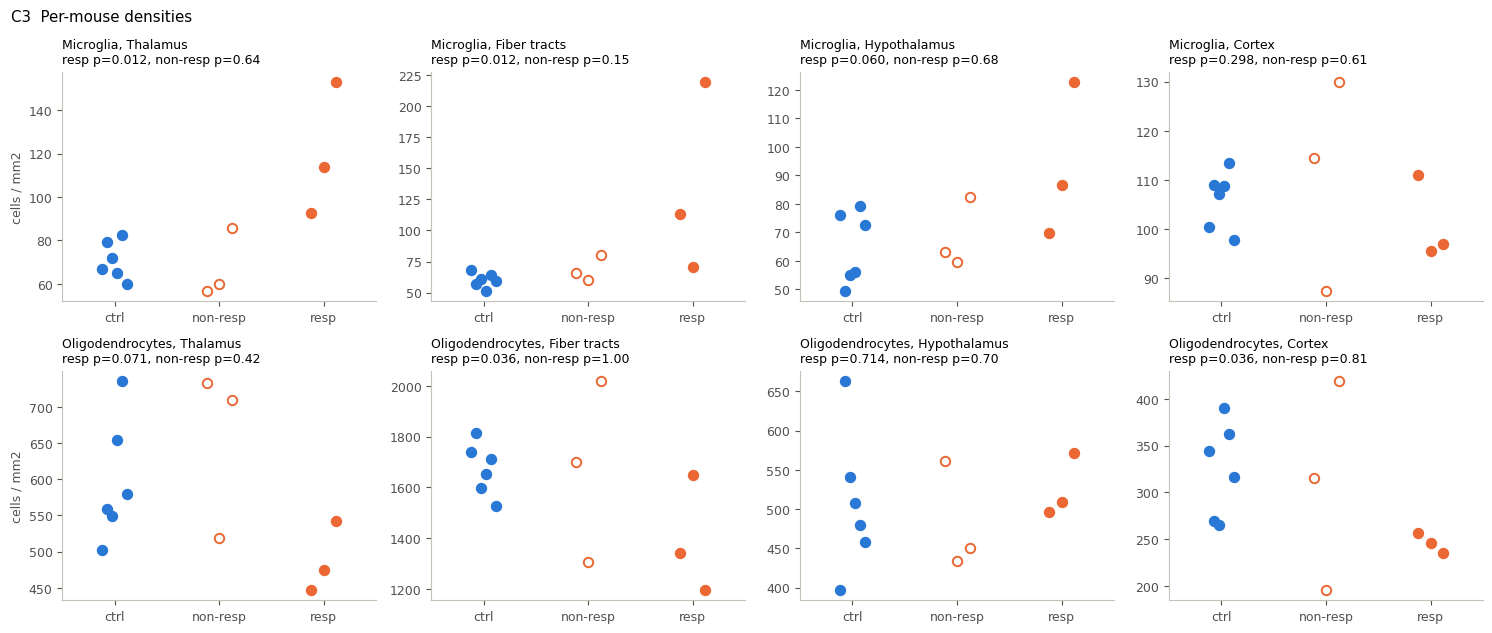

In [3]:
MAIN = ["Thalamus", "Fiber tracts", "Hypothalamus", "Striatum", "Cortex", "Hippocampus"]
TYPES = ["Microglia", "Oligodendrocytes", "Immature Oligodendrocytes I", "Astrocytes", "Endothelial Cells", "Excitatory Neurons", "Neurons"]
dens = co.region_density(cells)
save_table(dens.round(3), "density_long", index=False)
rows = []
for ct in TYPES:
    for r in MAIN:
        d = dens[(dens.cell_type == ct) & (dens.region == r)].set_index("sample_id").reindex(order)
        for metric in ("density", "share"):
            v = d[metric].fillna(0)
            dr, pr = co.exact_perm(v, resp, ctrl); dn, pn = co.exact_perm(v, nonr, ctrl)
            rows.append({"cell_type": ct, "region": r, "metric": metric, "ctrl_mean": v[ctrl].mean(), "resp_mean": v[resp].mean(),
                         "nonresp_mean": v[nonr].mean(), "log2_resp_vs_ctrl": np.log2(v[resp].mean() / v[ctrl].mean()), "p_resp": pr,
                         "log2_nonresp_vs_ctrl": np.log2(v[nonr].mean() / v[ctrl].mean()), "p_nonresp": pn})
stats = save_table(pd.DataFrame(rows).round(4), "density_tests", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"wspace": 0.05})
for ax, (col, pcol, lab) in zip(axes, [("log2_resp_vs_ctrl", "p_resp", "responders"), ("log2_nonresp_vs_ctrl", "p_nonresp", "non-responders")]):
    t = stats[stats.metric == "density"].pivot(index="cell_type", columns="region", values=col).loc[TYPES, MAIN]
    p = stats[stats.metric == "density"].pivot(index="cell_type", columns="region", values=pcol).loc[TYPES, MAIN]
    im = ax.imshow(t, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    for i in range(t.shape[0]):
        for j in range(t.shape[1]):
            ax.text(j, i, f"{t.iat[i, j]:+.2f}" + ("*" if p.iat[i, j] < 0.05 else ""), ha="center", va="center", fontsize=7)
    ax.set_xticks(range(len(MAIN)), MAIN, rotation=30, ha="right"); ax.set_yticks(range(len(TYPES)), TYPES if ax is axes[0] else [])
    ax.set_title(f"{lab} vs controls: log2 density ratio (* exact p < 0.05)", fontsize=9)
fig.colorbar(im, ax=axes, shrink=0.8, label="log2 (group mean / control mean)")
fig.suptitle("C2  Responders gain microglia in thalamus and fibre tracts; non-responders change nothing", x=0.01, ha="left")
save(fig, "C2_density_heatmap")

fig, axes = plt.subplots(2, 4, figsize=(15, 6.4))
for row, ct in enumerate(["Microglia", "Oligodendrocytes"]):
    for j, r in enumerate(["Thalamus", "Fiber tracts", "Hypothalamus", "Cortex"]):
        v = dens[(dens.cell_type == ct) & (dens.region == r)].set_index("sample_id")["density"].reindex(order).fillna(0)
        dots(axes[row, j], v, f"{ct}, {r}\n{ptxt(v)}", ylab="cells / mm2" if j == 0 else None)
fig.suptitle("C3  Per-mouse densities", x=0.01, ha="left"); fig.tight_layout(); save(fig, "C3_density_dots")
display(stats[(stats.metric == "density") & (stats.p_resp < 0.1)].sort_values("p_resp"))

**B.** The one robust change is **microglia: in thalamus 92-153 /mm2 in responders vs 60-82 in controls, in fibre
tracts 71-219 vs 51-68** (both complete separation, p = 0.012), with hypothalamus in the same direction (p = 0.06).
Cortex, striatum and hippocampus have no change. Non-responders are within the control range everywhere.
OL (+ DA-OL) density is modestly lower in responder cortex (235-256 vs 266-391 /mm2) and fibre tracts
(1,197-1,648 vs 1,527-1,814), both p = 0.036, i.e. some OL loss is possible but the ranges overlap; immature OLs,
astrocytes and endothelial cells are unchanged. Neuron densities are noisy (few neurons in some regions), but
"Neurons" in responder fibre tracts are 3.7x controls (p = 0.024): grey-matter cells being called fibre tract, which
fits the pallidum gap in A. The fibre-tract microglia range is wide because RB4405
(P60) has 219 /mm2, the highest by far, while RB4401 (P60) is at 71, just above controls.

## C. Without region labels: microglia in OL-rich tissue

squares per section,0%-10%,10%-30%,30%-50%,50%-100%
sample_id,,,,
RB4620,1038,905,174,189
RB4658,823,549,222,170
RB4676,1009,815,275,187
RB4282,882,777,265,186
RB4350,803,704,204,163
RB4498,916,797,245,173
RB4630,859,581,238,131
RB4653,1090,585,239,165
RB4403,1259,1161,329,231


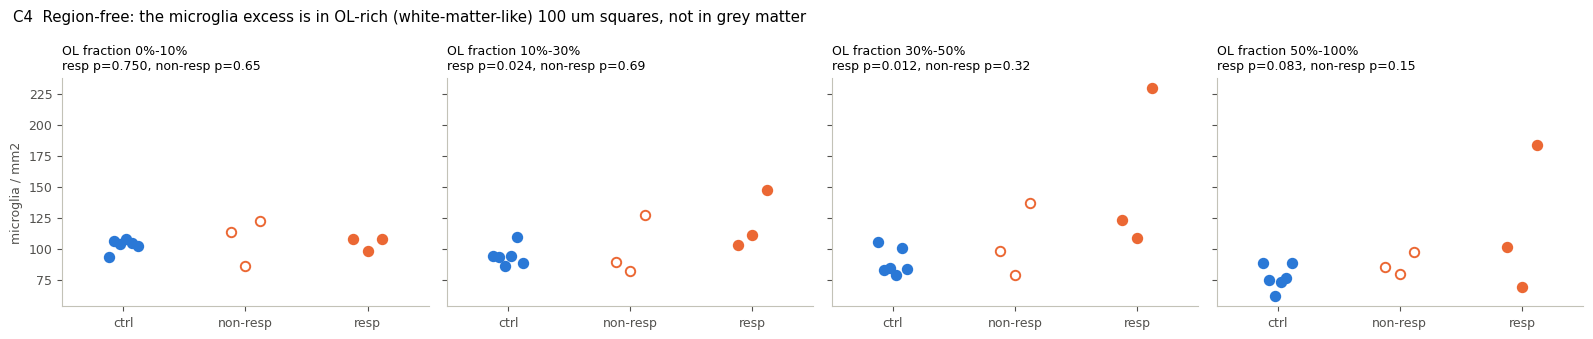

In [4]:
is_ol = cells.cell_type == "Oligodendrocytes"
b = co.ol_rich_bins(cells, is_ol, cells.cell_type == "Microglia", bin=100)
bt = b.pivot(index="sample_id", columns="ol_frac", values="density").loc[order]
save_table(bt.round(1), "microglia_density_by_ol_fraction")
fig, axes = plt.subplots(1, bt.shape[1], figsize=(4 * bt.shape[1], 3.4), sharey=True)
for ax, col in zip(axes, bt.columns):
    dots(ax, bt[col], f"OL fraction {col}\n{ptxt(bt[col])}", ylab="microglia / mm2" if ax is axes[0] else None)
fig.suptitle("C4  Region-free: the microglia excess is in OL-rich (white-matter-like) 100 um squares, not in grey matter", x=0.01, ha="left")
fig.tight_layout(); save(fig, "C4_microglia_by_ol_fraction")
display(b.pivot(index="sample_id", columns="ol_frac", values="n_bins").loc[order].rename_axis(columns="squares per section"))

**C.** Ignoring region labels and splitting each section into 100 um squares by the share of their cells that are
OLs, responders have more microglia in squares that are 10-30 % OL (p = 0.024) and 30-50 % OL (p = 0.012), with
the same direction above 50 % (p = 0.08), and none in OL-poor (< 10 %, grey-matter-like) squares. So the
microgliosis is a white-matter phenomenon that does not depend on how the regions were drawn. Per mouse it is graded:
RB4405 >> RB4627 > RB4401; RB4401 is barely above controls in the purest white matter, consistent with it being the
mildest responder by OL ISR too (analysis/07).

## D. Are the extra microglia proliferating?

,n,observed,expected,obs_over_exp,prolif_per_mm2_section,group
sample_id,,,,,,
RB4620,2316,0.115,0.119,0.968,10.757,control
RB4658,1920,0.109,0.120,0.907,9.827,control
RB4676,2424,0.133,0.127,1.046,12.010,control
RB4282,2188,0.112,0.129,0.874,10.621,control
RB4350,2190,0.126,0.121,1.048,12.929,control
RB4498,2225,0.146,0.128,1.135,13.226,control
RB4630,1988,0.130,0.133,0.981,13.201,non-responder
RB4653,2048,0.137,0.131,1.051,11.153,non-responder
RB4403,3783,0.146,0.147,0.988,17.917,non-responder


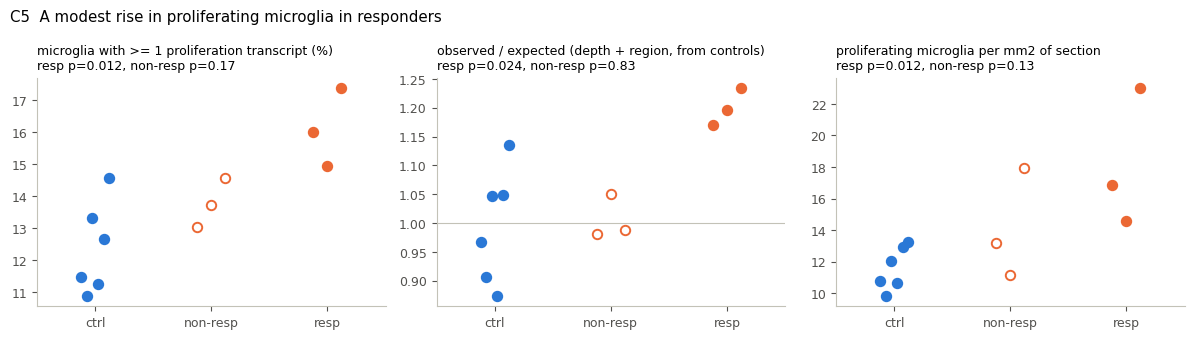

In [5]:
mg = cells[cells.cell_type == "Microglia"].copy()
mg["prolif"] = (mg.PROLIF > 0).astype(int)
mg["log_counts"] = np.log(mg.total_counts)
# expected proliferation-gene detection from the controls (depends on depth and region), then observed / expected
ref = mg[mg.sample_id.isin(ctrl)]
X = lambda d: sm.add_constant(pd.get_dummies(d.region, drop_first=False, dtype=float).reindex(columns=sorted(mg.region.unique()), fill_value=0)
                              .assign(log_counts=d.log_counts.to_numpy()), has_constant="add")
fit = sm.GLM(ref.prolif, X(ref), family=sm.families.Binomial()).fit()
mg["expected"] = fit.predict(X(mg))
pro = mg.groupby("sample_id").agg(n=("prolif", "size"), observed=("prolif", "mean"), expected=("expected", "mean")).loc[order]
pro["obs_over_exp"] = pro.observed / pro.expected
pro["prolif_per_mm2_section"] = mg[mg.prolif == 1].groupby("sample_id").size().reindex(order) / co.occupied_area(cells, ("sample_id",)).reindex(order)
save_table(pro.round(4), "microglia_proliferation")
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
dots(axes[0], 100 * pro.observed, f"microglia with >= 1 proliferation transcript (%)\n{ptxt(pro.observed)}")
dots(axes[1], pro.obs_over_exp, f"observed / expected (depth + region, from controls)\n{ptxt(pro.obs_over_exp)}", ref=1)
dots(axes[2], pro.prolif_per_mm2_section, f"proliferating microglia per mm2 of section\n{ptxt(pro.prolif_per_mm2_section)}")
fig.suptitle("C5  A modest rise in proliferating microglia in responders", x=0.01, ha="left"); fig.tight_layout(); save(fig, "C5_microglia_proliferation")
display(pro.round(3).assign(group=grp))

**D.** 15-17 % of responder microglia carry at least one proliferation transcript (Mki67, Top2a, Cdk1, Pcna, ...)
against 11-15 % in controls (p = 0.012); after adjusting for sequencing depth and region, observed / expected is
1.17-1.23 in responders against 0.87-1.14 in controls (p = 0.012) and ~1 in non-responders. Combined with the higher density, responders have more proliferating microglia per mm2. A single
transcript is a weak call (the panel lacks several cell-cycle genes), so this supports local proliferation as a
contributor to the microgliosis without proving it; Ki67/Iba1 co-staining would.

## E. Are microglia concentrated around stressed OLs?

band,<50,50-90,90-95,95-99,>99,group
sample_id,,,,,,
RB4620,1.0,1.01,1.08,0.96,1.14,control
RB4658,1.0,1.05,1.12,1.23,1.01,control
RB4676,1.0,1.07,1.13,1.08,1.01,control
RB4282,1.0,1.01,1.04,1.08,1.09,control
RB4350,1.0,1.00,0.94,1.02,1.15,control
RB4498,1.0,1.04,0.98,1.02,0.90,control
RB4630,1.0,1.01,0.97,1.06,0.96,non-responder
RB4653,1.0,1.06,0.93,0.92,1.24,non-responder
RB4403,1.0,1.01,0.97,0.92,1.07,non-responder


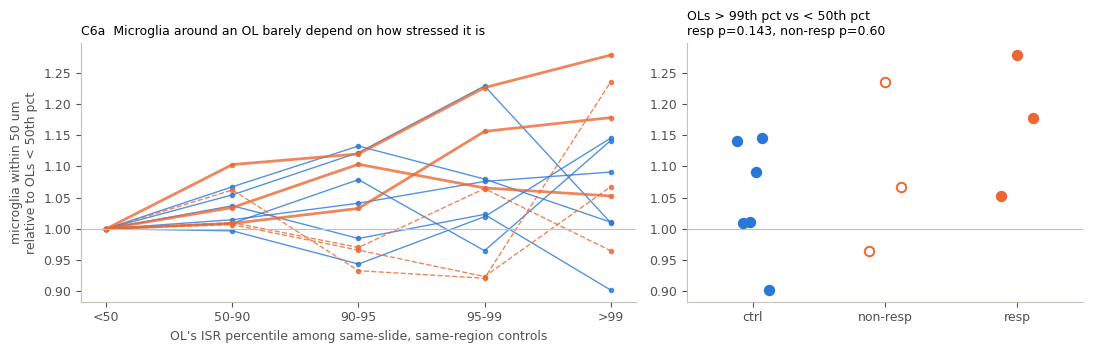

In [6]:
ol = pd.read_csv(REPO / "results" / "cell_table" / "ol_gene_scores.csv.gz")
ol = ol[ol.region != "Unknown"].reset_index(drop=True)
ol["u"] = mo.loo_percentiles(ol, "isr", grp, sections["age"])
ol = ol.merge(cells[["cell_id", "sample_id", "x_centroid", "y_centroid"]], on=["cell_id", "sample_id"])
parts = []
for sid, o in ol.groupby("sample_id"):
    sec = cells[cells.sample_id == sid]
    parts.append(o.assign(n_mg=co.neighbour_counts(o, sec[sec.cell_type == "Microglia"]), n_all=co.neighbour_counts(o, sec)))
ol = pd.concat(parts)
ol["band"] = pd.cut(ol.u, [0, 0.5, 0.9, 0.95, 0.99, 1.0], labels=["<50", "50-90", "90-95", "95-99", ">99"], include_lowest=True)
# within section x region: microglia around OLs in each ISR band relative to OLs below the control median
rel = (ol.groupby(["sample_id", "region", "band"], observed=True).n_mg.agg(["mean", "size"]).reset_index())
base = rel[rel.band == "<50"].set_index(["sample_id", "region"])["mean"]
rel["ratio"] = rel["mean"] / rel.set_index(["sample_id", "region"]).index.map(base)
rel = rel[(rel["size"] >= 10) & rel.ratio.notna() & np.isfinite(rel.ratio)]
w = rel.groupby(["sample_id", "band"], observed=True).apply(lambda d: np.average(d.ratio, weights=d["size"]), include_groups=False).unstack().loc[order]
save_table(w.round(3), "microglia_near_ol_by_isr_band")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.4, 1]})
for s in order:
    axes[0].plot(range(w.shape[1]), w.loc[s], marker="o", ms=3, color=BLUE if grp[s] == "control" else ORANGE,
                 ls="--" if grp[s] == "non-responder" else "-", lw=2 if grp[s] == "responder" else 1, alpha=0.8)
axes[0].axhline(1, color=AXIS, lw=0.8); axes[0].set_xticks(range(w.shape[1]), [f"{c}" for c in w.columns])
axes[0].set_xlabel("OL's ISR percentile among same-slide, same-region controls"); axes[0].set_ylabel("microglia within 50 um\nrelative to OLs < 50th pct")
axes[0].set_title("C6a  Microglia around an OL barely depend on how stressed it is", fontsize=9)
dots(axes[1], w[">99"], f"OLs > 99th pct vs < 50th pct\n{ptxt(w['>99'].fillna(1))}", ref=1)
fig.tight_layout(); save(fig, "C6_microglia_near_stressed_ols")
display(w.round(2).assign(group=grp))

**E.** Within the same section and region, an OL above the control 99th ISR percentile has only ~5-25 % more
microglia within 50 um than an OL below the median, and controls show the same mild gradient for their own
"top" OLs (expression and cell crowding co-vary). Responders are not clearly above controls on this measure, so the
extra microglia are **spread through the affected white matter rather than clustered on the most stressed OLs**.
This agrees with analysis/04 (DAM couples only weakly to local OL stress) and with finding 9 (diffuse, not focal).

## F. Maps

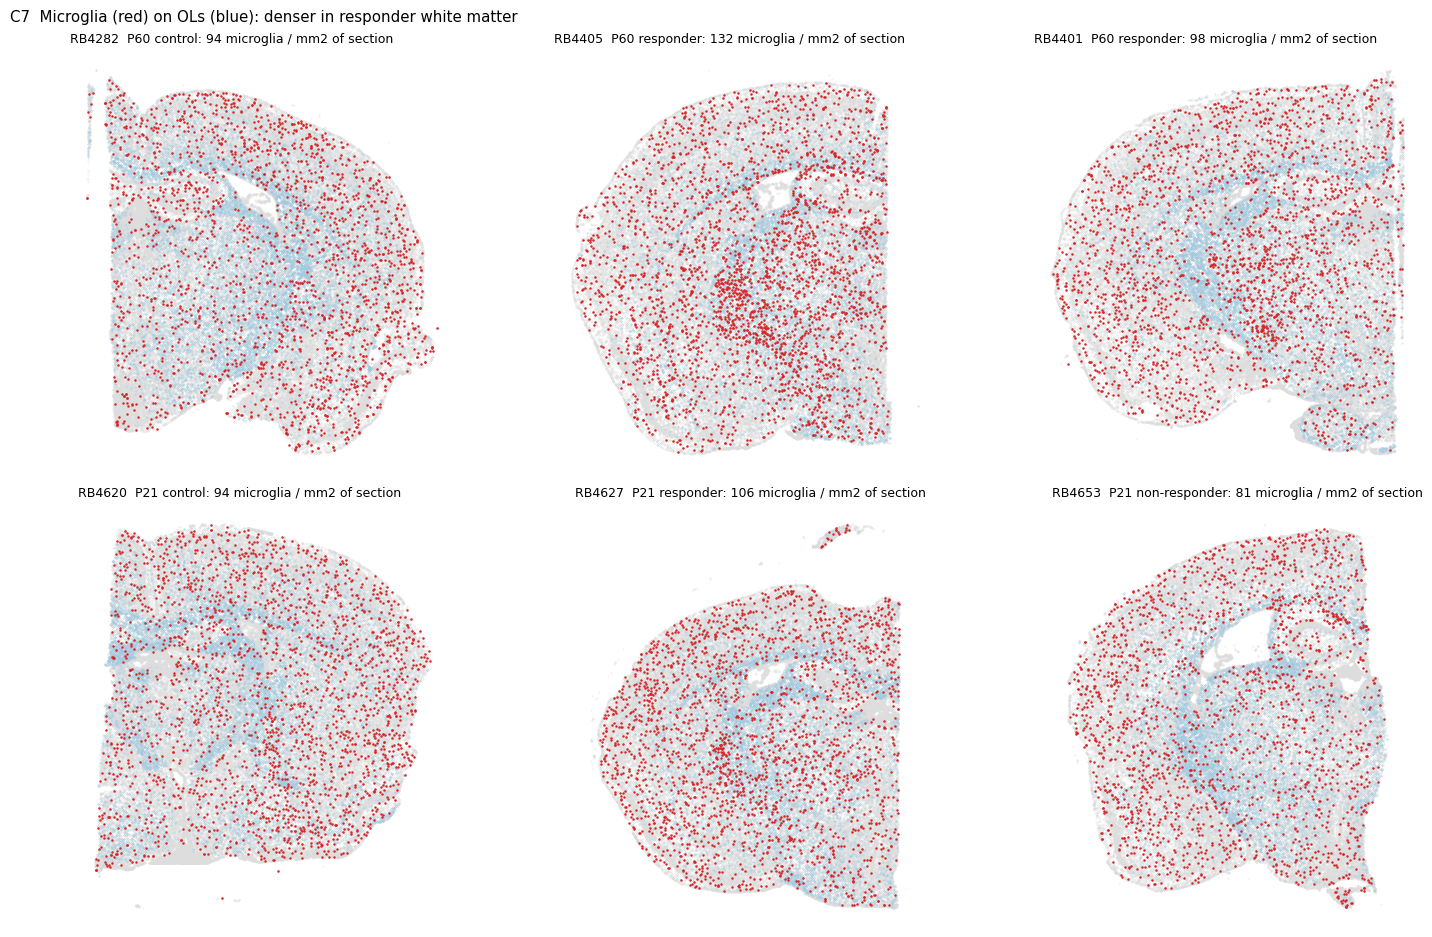

In [7]:
PAIRS = [("RB4282", "P60 control"), ("RB4405", "P60 responder"), ("RB4401", "P60 responder"),
         ("RB4620", "P21 control"), ("RB4627", "P21 responder"), ("RB4653", "P21 non-responder")]
fig, axes = plt.subplots(2, 3, figsize=(15, 9.5))
for ax, (s, lab) in zip(axes.ravel(), PAIRS):
    sec = cells[cells.sample_id == s]
    ax.scatter(sec.x_centroid, sec.y_centroid, s=0.05, color="#dddddd", rasterized=True)
    o = sec[sec.cell_type == "Oligodendrocytes"]
    ax.scatter(o.x_centroid, o.y_centroid, s=0.05, color="#9ecae1", rasterized=True)
    m = sec[sec.cell_type == "Microglia"]
    ax.scatter(m.x_centroid, m.y_centroid, s=0.6, color="#d62728", rasterized=True)
    a = co.occupied_area(sec, ("sample_id",)).iloc[0]
    ax.set_title(f"{s}  {lab}: {len(m) / a:.0f} microglia / mm2 of section", fontsize=9)
    ax.set_aspect("equal"); ax.invert_yaxis(); ax.axis("off")
fig.suptitle("C7  Microglia (red) on OLs (blue): denser in responder white matter", x=0.01, ha="left")
fig.tight_layout(); save(fig, "C7_maps", dpi=150)

**F.** In RB4405 and RB4627 the extra microglia concentrate in the thalamus and the white matter around it, with a dense
thalamic patch in RB4405; RB4401 shows a smaller thalamic patch. Whole-section densities hide this (RB4401 98 vs control 94 /mm2).

## Summary

* **Microgliosis in responders**, confined to white-matter-rich tissue (thalamus, fibre tracts, hypothalamus;
  OL-rich squares regardless of labels): ~1.5-3x the control density, graded RB4405 > RB4627 > RB4401. None in
  non-responders. A cellular readout to check by Iba1 counts, alongside the DAM state change.
* **Modestly more proliferating microglia**, so local expansion probably contributes.
* **Not clustered on stressed OLs**: the increase is region-wide, matching the diffuse OL response.
* **OL loss at most modest** (cortex and fibre tracts, overlapping ranges); OL + DA-OL counted together.
* **Caveat**: pallidum is almost missing from the responder sections. Whether that is section plane or disease
  shifting the transcript-based region map matters for every region-level result; the label-free analysis (C)
  shows the microglia result does not depend on it.